# From Barrel to Pump: Data Analysis
**Madeline Boss**

Research question: *How closely do U.S. retail gas prices follow the cost of crude oil, and how quickly do pump prices react when oil prices change?*

This notebook covers Section 3.3. It uses the cleaned table from `01_data_collection_and_cleaning.ipynb` and works through four questions:

1. **How have prices and the spread changed over time?** (exploratory data analysis)
2. **How strongly do gas and crude move together?** (correlation)
3. **How much of a \$1 change in crude reaches the pump, and how fast?** (regression and lag analysis)
4. **Do pump prices rise faster than they fall?** ("rockets and feathers" test)

Run notebook 01 first. This notebook needs `statsmodels`. If it is not installed in your environment, run `pip install statsmodels` in the terminal first.

## Task 1: Setup

In [2]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint

for m in (pd, np, plt.matplotlib, statsmodels):
    print(m.__name__, m.__version__)

pandas 3.0.6
numpy 2.4.6
matplotlib 3.11.2
statsmodels 0.15.0


In [3]:
PROCESSED = "data/processed"
FRONTEND_DATA = "frontend/data"
FIGURES = "figures"
for folder in (FRONTEND_DATA, FIGURES):
    os.makedirs(folder, exist_ok=True)

df = pd.read_csv(os.path.join(PROCESSED, "weekly_prices.csv"), parse_dates=["date"]).set_index("date")
print(f"{df.shape[0]} weeks, {df.index.min().date()} to {df.index.max().date()}")
print(df[["regular", "crude_gal", "spread_regular"]].tail())

1819 weeks, 1990-08-20 to 2025-06-23
            regular  crude_gal  spread_regular
date                                          
2025-05-26    3.160     1.5063          1.6537
2025-06-02    3.127     1.4718          1.6552
2025-06-09    3.108     1.5252          1.5828
2025-06-16    3.139     1.6340          1.5050
2025-06-23    3.213     1.7843          1.4287


## Task 2: Exploratory Data Analysis

**Why EDA first:** before testing any relationship, I need to know the scale of each series, how they change over time, and whether the gap between them is stable. These patterns decide which methods make sense later. For example, if both prices trend upward, a simple correlation of price levels will be misleading.

### Task 2.1: Summary statistics

In [4]:
#nominal dollars
print("Nominal $/gallon")
print(df[["regular", "crude_gal", "spread_regular"]].describe().round(3))

#inflation-adjusted (June 2025) dollars
print("\nReal $/gallon (June 2025 dollars)")
print(df[["regular_real", "crude_gal_real", "spread_regular_real"]].describe().round(3))

Nominal $/gallon
        regular  crude_gal  spread_regular
count  1813.000   1819.000        1813.000
mean      2.240      1.236           1.002
std       0.953      0.694           0.338
min       0.907      0.261           0.389
25%       1.236      0.557           0.705
50%       2.240      1.168           0.924
75%       3.046      1.766           1.232
max       5.006      3.393           2.303

Real $/gallon (June 2025 dollars)
       regular_real  crude_gal_real  spread_regular_real
count      1813.000        1819.000             1813.000
mean          3.324           1.810                1.513
std           0.941           0.839                0.244
min           1.778           0.401                0.833
25%           2.519           1.143                1.352
50%           3.136           1.613                1.449
75%           3.905           2.337                1.618
max           6.036           4.976                2.642


*Interpretation (fill in after running): Compare the nominal and real tables. How different are the averages once inflation is removed? What is the typical spread, and how much does it vary (std, min, max)?*

### Task 2.2: Averages by decade

In [5]:
df["decade"] = (df.index.year // 10) * 10
df["crude_share"] = df["crude_gal"] / df["regular"]     #share of the pump price that is crude oil

by_decade = (df.groupby("decade")
               .agg(weeks=("regular", "count"),
                    gas_real=("regular_real", "mean"),
                    crude_real=("crude_gal_real", "mean"),
                    spread_real=("spread_regular_real", "mean"),
                    crude_share_pct=("crude_share", "mean"))
               .round(3))
by_decade["crude_share_pct"] = (by_decade["crude_share_pct"] * 100).round(1)
print(by_decade)

        weeks  gas_real  crude_real  spread_real  crude_share_pct
decade                                                           
1990      483     2.389       1.010        1.386             41.5
2000      522     3.426       1.971        1.455             55.5
2010      522     3.982       2.370        1.612             58.1
2020      286     3.515       1.860        1.654             52.2


*Interpretation (fill in after running): Which decade had the highest real gas price? How did crude's share of the pump price change from the 1990s to the 2010s? Note that the 1990s start in August 1990 and the 2020s end in June 2025.*

### Task 2.3: Chart 1, real prices over time

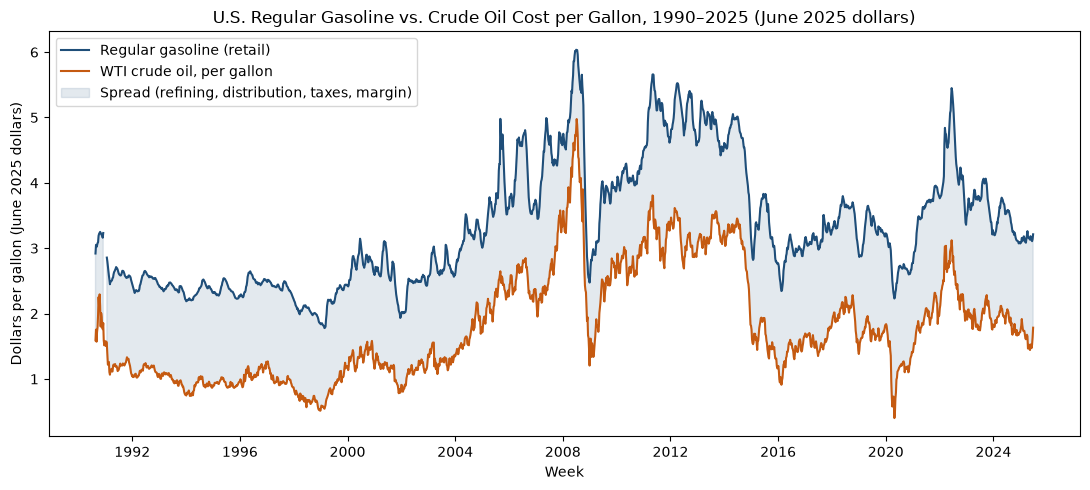

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df.index, df["regular_real"], label="Regular gasoline (retail)", color="#1f4e79")
ax.plot(df.index, df["crude_gal_real"], label="WTI crude oil, per gallon", color="#c55a11")
ax.fill_between(df.index, df["crude_gal_real"], df["regular_real"], color="#1f4e79", alpha=0.12,
                label="Spread (refining, distribution, taxes, margin)")
ax.set_title("U.S. Regular Gasoline vs. Crude Oil Cost per Gallon, 1990–2025 (June 2025 dollars)")
ax.set_xlabel("Week")
ax.set_ylabel("Dollars per gallon (June 2025 dollars)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart1_real_prices.png"), dpi=150)
plt.show()

*Interpretation (fill in after running): Shows: ... Hides: ... (Compare with the nominal chart in notebook 01. Does the long upward trend shrink once inflation is removed?)*

### Task 2.4: Chart 2, the spread over time

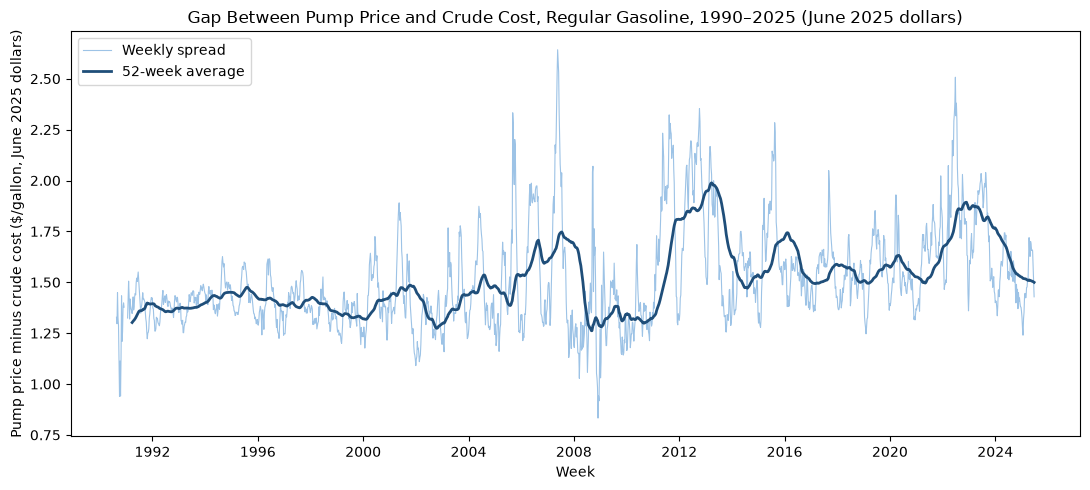

In [7]:
#52-week rolling average smooths out weekly noise and seasonal swings
spread_smooth = df["spread_regular_real"].rolling(52, min_periods=26).mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df.index, df["spread_regular_real"], color="#9dc3e6", linewidth=0.8, label="Weekly spread")
ax.plot(df.index, spread_smooth, color="#1f4e79", linewidth=2, label="52-week average")
ax.set_title("Gap Between Pump Price and Crude Cost, Regular Gasoline, 1990–2025 (June 2025 dollars)")
ax.set_xlabel("Week")
ax.set_ylabel("Pump price minus crude cost ($/gallon, June 2025 dollars)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart2_spread.png"), dpi=150)
plt.show()

*Interpretation (fill in after running): Shows: ... Hides: ... (Is the spread stable, rising or falling? Look for spikes when crude fell quickly, such as late 2008 and spring 2020. That is a first hint of 'rockets and feathers'.)*

## Task 3: Correlation

**Method:** Pearson correlation measures how closely two variables follow a straight-line relationship. Spearman correlation does the same using ranks, so it is less affected by extreme weeks.

**Why two versions:** gas and crude both trend upward over 35 years. Any two upward-trending series will show a high correlation in *levels* even if they are unrelated, a problem called spurious correlation. So I also correlate *weekly changes*: if gas really follows crude, the weeks when crude rises should be the weeks when gas rises.

In [10]:
levels = df[["regular", "crude_gal"]].dropna()
r_lvl, p_lvl = stats.pearsonr(levels["regular"], levels["crude_gal"])
rho_lvl, _ = stats.spearmanr(levels["regular"], levels["crude_gal"])

#weekly changes in dollars per gallon (diff skips across the 1990-91 gap automatically)
changes = df[["regular", "crude_gal"]].diff().dropna()
r_chg, p_chg = stats.pearsonr(changes["regular"], changes["crude_gal"])
rho_chg, _ = stats.spearmanr(changes["regular"], changes["crude_gal"])

#same-week change in gas vs. the previous week's change in crude
lagged = pd.concat([df["regular"].diff(), df["crude_gal"].diff().shift(1)], axis=1).dropna()
r_chg_lag1, _ = stats.pearsonr(lagged.iloc[:, 0], lagged.iloc[:, 1])

corr_table = pd.DataFrame({
    "pearson": [r_lvl, r_chg, r_chg_lag1],
    "spearman": [rho_lvl, rho_chg, np.nan],
    "n_weeks": [len(levels), len(changes), len(lagged)],
}, index=["price levels", "weekly changes (same week)", "weekly changes (crude 1 week earlier)"]).round(3)
print(corr_table)
print(f"\np-values: levels {p_lvl:.2g}, changes {p_chg:.2g}")

                                       pearson  spearman  n_weeks
price levels                             0.964     0.970     1813
weekly changes (same week)               0.551     0.529     1811
weekly changes (crude 1 week earlier)    0.392       NaN     1810

p-values: levels 0, changes 2.1e-144


*Interpretation (fill in after running): How much lower is the correlation of changes than of levels? Does it go up when crude is moved one week earlier? If so, gas reacts to crude with a delay, which Task 5 measures in detail.*

## Task 4: Pass-Through Regression

**Method:** ordinary least squares (OLS) regression of the pump price on the crude cost per gallon:

gas price = a + b × crude cost per gallon

- **b (slope)** is the pass-through: how many dollars gas rises for each \$1 rise in crude per gallon. A value of 1 means the full change reaches the pump.
- **a (intercept)** is the part of the price that does not depend on crude, roughly refining, distribution, taxes and margin.

**Why it is valid here:** regressing one trending series on another can produce spurious results. It is only meaningful if the two series are *cointegrated*, meaning they never drift apart permanently. I check this first with the Engle-Granger cointegration test. I also use Newey-West (HAC) standard errors, because weekly prices are autocorrelated (each week is close to the last), and ordinary standard errors would be too small.

In [11]:
#Engle-Granger cointegration test: null hypothesis = NOT cointegrated
coint_t, coint_p, coint_crit = coint(levels["regular"], levels["crude_gal"])
print(f"Cointegration test statistic: {coint_t:.3f}, p-value: {coint_p:.4f}")
print("Critical values (1%, 5%, 10%):", np.round(coint_crit, 3))

Cointegration test statistic: -3.748, p-value: 0.0159
Critical values (1%, 5%, 10%): [-3.902 -3.34  -3.047]


*Interpretation (fill in after running): Is the p-value below 0.05? If yes, gas and crude are cointegrated: they share a long-run relationship and the levels regression below is meaningful.*

In [12]:
X = sm.add_constant(levels["crude_gal"])
levels_model = sm.OLS(levels["regular"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
print(levels_model.summary().tables[1])
print(f"\nR-squared: {levels_model.rsquared:.3f}")

a = levels_model.params["const"]
b = levels_model.params["crude_gal"]
print(f"Pass-through: each $1.00 rise in crude per gallon goes with a ${b:.2f} rise in regular gas")
print(f"Non-crude part of the price (intercept): ${a:.2f} per gallon")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.6036      0.031     19.213      0.000       0.542       0.665
crude_gal      1.3219      0.031     42.357      0.000       1.261       1.383

R-squared: 0.929
Pass-through: each $1.00 rise in crude per gallon goes with a $1.32 rise in regular gas
Non-crude part of the price (intercept): $0.60 per gallon


*Interpretation (fill in after running): Report b and a with their confidence intervals. Is b close to 1? What share of the variation in gas prices does crude explain (R-squared)?*

### Chart 3: Crude cost vs. pump price

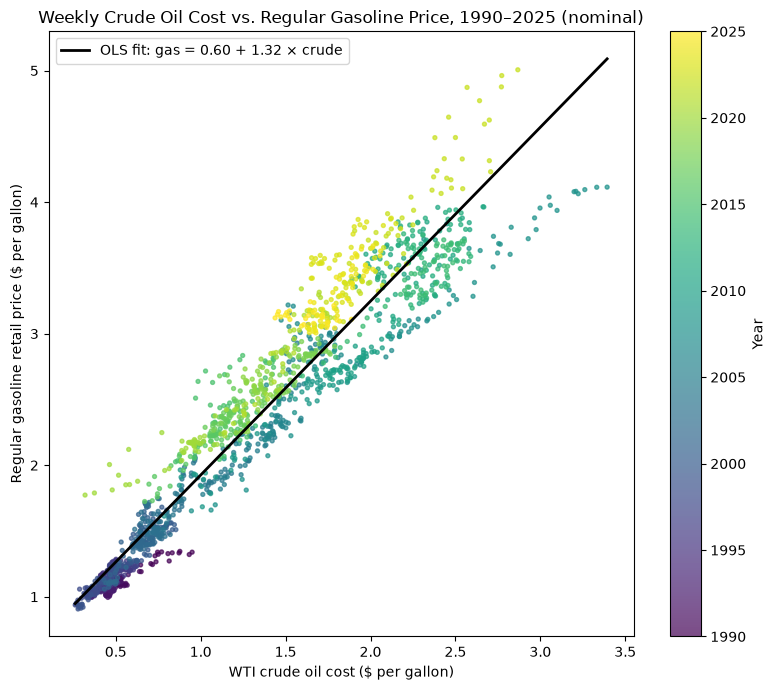

In [13]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(levels["crude_gal"], levels["regular"], c=levels.index.year, cmap="viridis", s=8, alpha=0.7)
x_line = np.linspace(levels["crude_gal"].min(), levels["crude_gal"].max(), 100)
ax.plot(x_line, a + b * x_line, color="black", linewidth=2,
        label=f"OLS fit: gas = {a:.2f} + {b:.2f} × crude")
ax.set_title("Weekly Crude Oil Cost vs. Regular Gasoline Price, 1990–2025 (nominal)")
ax.set_xlabel("WTI crude oil cost ($ per gallon)")
ax.set_ylabel("Regular gasoline retail price ($ per gallon)")
ax.legend(loc="upper left")
fig.colorbar(sc, ax=ax, label="Year")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart3_scatter.png"), dpi=150)
plt.show()

*Interpretation (fill in after running): Shows: ... Hides: ... (Do the points follow the line closely? Do recent years, in yellow, sit above the line, meaning a larger spread?)*

## Task 5: How Fast Do Pump Prices React?

**Method:** cross-correlation of weekly changes. I correlate this week's change in gas with the change in crude *k* weeks earlier, for k = 0 to 8. The lag with the highest correlation shows when crude changes have the most effect at the pump.

**Note on timing:** in notebook 01, each Monday's gas price was already matched with the *previous* week's average crude price. So lag 0 here already means "crude during the week before the survey," and lag 1 means two weeks before.

In [14]:
MAX_LAG = 8
d_gas = df["regular"].diff()
d_crude = df["crude_gal"].diff()

lag_corr = pd.Series({k: d_gas.corr(d_crude.shift(k)) for k in range(MAX_LAG + 1)}, name="correlation")
lag_corr.index.name = "lag_weeks"
print(lag_corr.round(3))
print(f"\nStrongest relationship at lag {lag_corr.idxmax()} weeks (r = {lag_corr.max():.3f})")

lag_weeks
0    0.551
1    0.392
2    0.222
3    0.174
4    0.137
5    0.106
6    0.077
7    0.052
8    0.050
Name: correlation, dtype: float64

Strongest relationship at lag 0 weeks (r = 0.551)


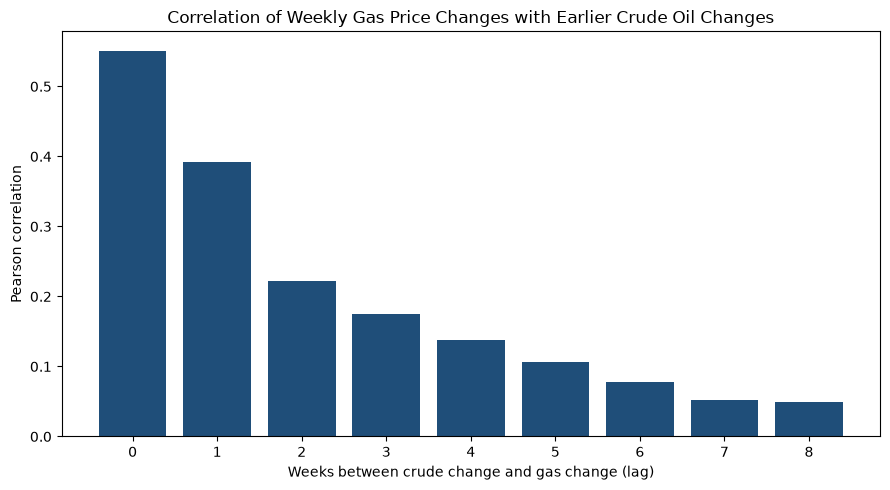

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(lag_corr.index, lag_corr.values, color="#1f4e79")
ax.set_xticks(lag_corr.index)
ax.set_title("Correlation of Weekly Gas Price Changes with Earlier Crude Oil Changes")
ax.set_xlabel("Weeks between crude change and gas change (lag)")
ax.set_ylabel("Pearson correlation")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart4_lag_correlation.png"), dpi=150)
plt.show()

*Interpretation (fill in after running): At which lag is the correlation highest, and how quickly does it fade? Translate it into days, remembering the one-week offset from the data alignment.*

## Task 6: Rockets and Feathers

**The question:** "Rockets and feathers" is the idea that gas prices shoot up like rockets when crude rises but drift down like feathers when it falls.

**Method:** a distributed-lag regression that lets increases and decreases in crude have *different* effects:

change in gas this week = c + Σₖ ( b⁺ₖ × crude increase k weeks ago + b⁻ₖ × crude decrease k weeks ago )

for k = 0 to 8 weeks. Each crude change is split into its positive part (an increase, otherwise 0) and its negative part (a decrease, otherwise 0).

Adding up the coefficients gives the **cumulative pass-through**: after *h* weeks, what share of a crude change has reached the pump? If increases pass through faster than decreases, the cumulative share for increases will be higher in the first few weeks.

**Why this method:** a single correlation or slope cannot tell increases apart from decreases, and it cannot show timing. This model answers both questions at once. To check whether the gap between increases and decreases is real or just noise, I use a t-test on the difference in cumulative pass-through at each week, again with Newey-West standard errors.

**Simplification:** the model does not include past gas changes or an error-correction term, which a full economics paper would add. It is kept simple so each coefficient is easy to read.

### Task 6.1: The model

In [16]:
def asymmetry_model(data, fuel="regular", max_lag=8, exclude=None):
    """Fit the increase/decrease distributed-lag model for one fuel.
    Returns the fitted model and a table of cumulative pass-through by week."""
    d_gas = data[fuel].diff().rename("d_gas")
    d_crude = data["crude_gal"].diff()
    up = d_crude.clip(lower=0)      #crude increases (0 in weeks it fell)
    down = d_crude.clip(upper=0)    #crude decreases (0 in weeks it rose)

    X = pd.DataFrame(index=data.index)
    for k in range(max_lag + 1):
        X[f"up_{k}"] = up.shift(k)
        X[f"down_{k}"] = down.shift(k)

    model_data = pd.concat([d_gas, X], axis=1)
    if exclude is not None:
        model_data = model_data[~exclude]
    model_data = model_data.dropna()

    model = sm.OLS(model_data["d_gas"], sm.add_constant(model_data.drop(columns="d_gas"))).fit(
        cov_type="HAC", cov_kwds={"maxlags": max_lag})

    #cumulative pass-through after h weeks, and a test of increase = decrease
    rows = []
    names = list(model.params.index)
    for h in range(max_lag + 1):
        weights = np.zeros(len(names))
        for k in range(h + 1):
            weights[names.index(f"up_{k}")] = 1
            weights[names.index(f"down_{k}")] = -1
        test = model.t_test(weights)
        cum_up = sum(model.params[f"up_{k}"] for k in range(h + 1))
        cum_down = sum(model.params[f"down_{k}"] for k in range(h + 1))
        rows.append({"week": h, "increase": cum_up, "decrease": cum_down,
                     "difference": cum_up - cum_down, "p_value": float(np.asarray(test.pvalue).ravel()[0])})
    return model, pd.DataFrame(rows).set_index("week")


model_reg, asym_reg = asymmetry_model(df, "regular")
print(f"Weeks used: {int(model_reg.nobs)}, R-squared: {model_reg.rsquared:.3f}")
print(asym_reg.round(3))

Weeks used: 1803, R-squared: 0.473
      increase  decrease  difference  p_value
week                                         
0        0.566     0.317       0.249    0.006
1        0.731     0.663       0.068    0.513
2        0.817     0.827      -0.010    0.939
3        0.835     0.964      -0.129    0.406
4        0.876     1.070      -0.194    0.196
5        0.921     1.100      -0.178    0.218
6        0.948     1.129      -0.181    0.224
7        1.005     1.113      -0.108    0.433
8        1.047     1.046       0.001    0.996


*Interpretation (fill in after running): Read the table row by row. In week 0 and week 1, what share of a crude increase has reached the pump, compared with a decrease? Is the difference significant (p < 0.05) in the early weeks? By week 8, have the two caught up?*

### Task 6.2: Chart 5, cumulative pass-through

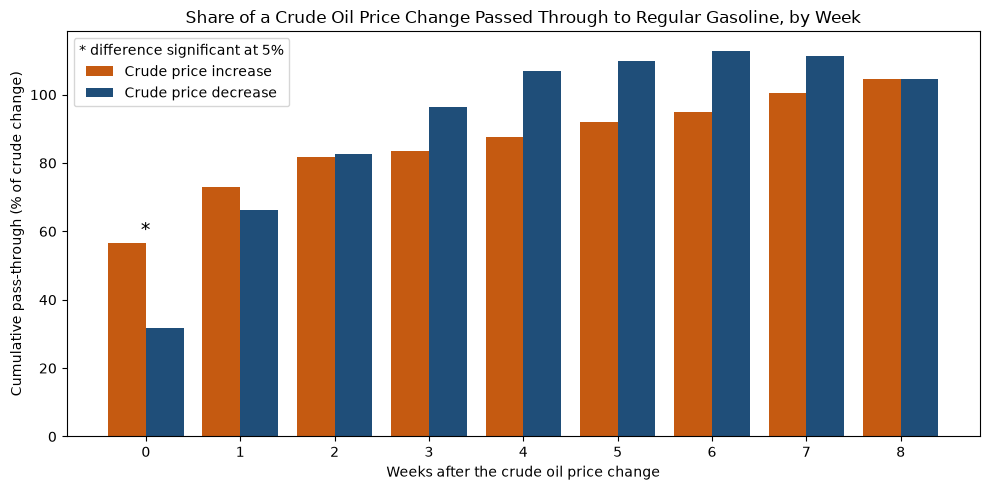

In [17]:
weeks = asym_reg.index.to_numpy()
width = 0.4

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(weeks - width / 2, asym_reg["increase"] * 100, width, color="#c55a11", label="Crude price increase")
ax.bar(weeks + width / 2, asym_reg["decrease"] * 100, width, color="#1f4e79", label="Crude price decrease")
for w, p in zip(weeks, asym_reg["p_value"]):
    if p < 0.05:
        top = max(asym_reg.loc[w, "increase"], asym_reg.loc[w, "decrease"]) * 100
        ax.text(w, top + 2, "*", ha="center", fontsize=14)
ax.set_xticks(weeks)
ax.set_title("Share of a Crude Oil Price Change Passed Through to Regular Gasoline, by Week")
ax.set_xlabel("Weeks after the crude oil price change")
ax.set_ylabel("Cumulative pass-through (% of crude change)")
ax.legend(title="* difference significant at 5%")
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, "chart5_rockets_feathers.png"), dpi=150)
plt.show()

*Interpretation (fill in after running): Shows: ... Hides: ... (Do the orange bars climb faster than the blue ones? This chart is the main finding and the basis for the bar chart on the website.)*

### Task 6.3: Robustness check without flagged weeks

Notebook 01 flagged 15 weeks with extreme moves (Hurricane Katrina, the 2008 crash, March–May 2020 and others) but kept them. Here I rerun the model without those weeks to check that the result is not driven by a few extreme events.

In [18]:
flagged = df["flag_regular_jump"].astype(bool) | df["flag_crude_jump"].astype(bool)
_, asym_robust = asymmetry_model(df, "regular", exclude=flagged)

compare = pd.DataFrame({
    "increase_all": asym_reg["increase"],
    "decrease_all": asym_reg["decrease"],
    "increase_no_flags": asym_robust["increase"],
    "decrease_no_flags": asym_robust["decrease"],
    "p_no_flags": asym_robust["p_value"],
}).round(3)
print(f"Weeks excluded: {int(flagged.sum())}")
print(compare)

Weeks excluded: 15
      increase_all  decrease_all  increase_no_flags  decrease_no_flags  \
week                                                                     
0            0.566         0.317              0.484              0.345   
1            0.731         0.663              0.660              0.665   
2            0.817         0.827              0.783              0.815   
3            0.835         0.964              0.802              0.930   
4            0.876         1.070              0.836              1.017   
5            0.921         1.100              0.889              1.031   
6            0.948         1.129              0.890              1.081   
7            1.005         1.113              0.943              1.056   
8            1.047         1.046              0.997              0.973   

      p_no_flags  
week              
0          0.047  
1          0.954  
2          0.776  
3          0.353  
4          0.176  
5          0.240  
6          0.1

*Interpretation (fill in after running): Does the gap between increases and decreases keep the same direction and roughly the same size without the flagged weeks? If so, the finding is not caused by a handful of extreme events.*

### Task 6.4: Other fuels

In [19]:
asym_by_fuel = {"regular": asym_reg}
for fuel in ["midgrade", "premium", "diesel"]:
    _, asym_by_fuel[fuel] = asymmetry_model(df, fuel)

#week 1 and week 4 summary for each fuel
summary_rows = []
for fuel, table in asym_by_fuel.items():
    for w in (1, 4):
        summary_rows.append({"fuel": fuel, "week": w,
                             "increase": table.loc[w, "increase"],
                             "decrease": table.loc[w, "decrease"],
                             "p_value": table.loc[w, "p_value"]})
print(pd.DataFrame(summary_rows).round(3).to_string(index=False))

    fuel  week  increase  decrease  p_value
 regular     1     0.731     0.663    0.513
 regular     4     0.876     1.070    0.196
midgrade     1     0.729     0.616    0.306
midgrade     4     0.883     1.039    0.308
 premium     1     0.725     0.611    0.300
 premium     4     0.880     1.041    0.293
  diesel     1     0.885     0.518    0.034
  diesel     4     1.017     0.891    0.375


*Interpretation (fill in after running): Does the same pattern appear for midgrade, premium and diesel? (These series start in 1994, so they cover fewer weeks than regular.)*

## Task 7: Save Results for the Website

The website's bar chart and summary text read these numbers from `frontend/data/analysis_results.json`, so the site always matches this notebook. Rerunning the notebook updates the file.

In [20]:
def table_to_records(table):
    return [{"week": int(w),
             "increase": round(float(r["increase"]), 4),
             "decrease": round(float(r["decrease"]), 4),
             "p_value": round(float(r["p_value"]), 4)}
            for w, r in table.iterrows()]

results = {
    "date_range": [df.index.min().strftime("%Y-%m-%d"), df.index.max().strftime("%Y-%m-%d")],
    "correlation": {
        "levels_pearson": round(float(r_lvl), 4),
        "changes_pearson": round(float(r_chg), 4),
        "changes_pearson_crude_1wk_earlier": round(float(r_chg_lag1), 4),
    },
    "cointegration_p_value": round(float(coint_p), 4),
    "levels_regression": {
        "slope": round(float(b), 4),
        "intercept": round(float(a), 4),
        "r_squared": round(float(levels_model.rsquared), 4),
    },
    "lag_correlation": [{"lag": int(k), "correlation": round(float(v), 4)} for k, v in lag_corr.items()],
    "asymmetry": {fuel: table_to_records(t) for fuel, t in asym_by_fuel.items()},
}

with open(os.path.join(FRONTEND_DATA, "analysis_results.json"), "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2)[:1500])

{
  "date_range": [
    "1990-08-20",
    "2025-06-23"
  ],
  "correlation": {
    "levels_pearson": 0.9638,
    "changes_pearson": 0.5511,
    "changes_pearson_crude_1wk_earlier": 0.3916
  },
  "cointegration_p_value": 0.0159,
  "levels_regression": {
    "slope": 1.3219,
    "intercept": 0.6036,
    "r_squared": 0.9289
  },
  "lag_correlation": [
    {
      "lag": 0,
      "correlation": 0.5511
    },
    {
      "lag": 1,
      "correlation": 0.3916
    },
    {
      "lag": 2,
      "correlation": 0.2219
    },
    {
      "lag": 3,
      "correlation": 0.1743
    },
    {
      "lag": 4,
      "correlation": 0.1374
    },
    {
      "lag": 5,
      "correlation": 0.1058
    },
    {
      "lag": 6,
      "correlation": 0.0774
    },
    {
      "lag": 7,
      "correlation": 0.0517
    },
    {
      "lag": 8,
      "correlation": 0.0495
    }
  ],
  "asymmetry": {
    "regular": [
      {
        "week": 0,
        "increase": 0.5662,
        "decrease": 0.3169,
        "p_valu

## Summary of Findings

*Fill in after running. One or two sentences each, with the key number:*

1. **Long-run relationship:** gas and crude are / are not cointegrated (p = ...). Each \$1.00 rise in crude per gallon goes with about \$... at the pump, and crude explains ...% of the variation in gas prices.
2. **Speed:** weekly gas changes are most strongly related to crude changes ... week(s) earlier (r = ...).
3. **Rockets and feathers:** after one week, about ...% of a crude increase has reached the pump, compared with ...% of a decrease. The difference is / is not significant, and it disappears after about ... weeks. The result holds / does not hold without the 15 flagged weeks.
4. **The spread:** in real terms, the gap between pump price and crude cost has ... since the 1990s.

### Limitations
- **National averages only:** regional differences, such as California's higher taxes and fuel standards, are not visible.
- **WTI is one benchmark:** refiners also buy imported crude and Brent-priced crude, which can differ from WTI, especially in 2011–2014.
- **Crude is not the only cost:** refinery outages (Katrina, Harvey), seasonal fuel blends and taxes also move pump prices. The models here only look at crude.
- **Simplified model:** the asymmetry model leaves out past gas changes and an error-correction term, so its coefficients are a clear description rather than a full economic model.
- **Data ends June 2025.**